In [28]:
# ---------------------------------------------------------
# STEP 1: SETUP & LOAD
# ---------------------------------------------------------

# 1. Imports - Bring in the standard data science tools
# Pandas: For creating and manipulating tables (DataFrames)
# NumPy: For math operations
# Matplotlib & Seaborn: For creating charts and graphs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Configure Pandas Display Settings
# Stop Pandas from using scientific notation
# Forces numbers to look like normal decimals
pd.set_option('display.float_format', '{:.6f}'.format)

# Force Pandas to show all column headers when we run .head()
pd.set_option('display.max_columns', None)

# Increase the number of rows displayed so we can see more data at once
pd.set_option("display.max_rows", 200)

# 3. Load the full dataset
# Read the raw CSV file into a variable named 'owid'
# Note: The CSV file must be in the same folder as this notebook for this to work
owid = pd.read_csv("owid-energy-data.csv")

# 4. Load Success Check 
# Print the shape to confirm data loaded correctly (Rows, Columns)
print("Data loaded successfully! Shape:", owid.shape)

# ---------------------------------------------------------
# STEP 2: DATA EXPLORATION
# ---------------------------------------------------------

# 1. The Column Names in the owid file
# Below is the FULL list of variables available to the team
# We have grouped them by category so you can copy & paste the exact name you need

# --- BASIC INFO ---
# 'country', 'year', 'iso_code', 'population', 'gdp'

# --- BIOFUEL ---
# 'biofuel_cons_change_pct', 'biofuel_cons_change_twh', 'biofuel_cons_per_capita', 
# 'biofuel_consumption', 'biofuel_elec_per_capita', 'biofuel_electricity', 
# 'biofuel_share_elec', 'biofuel_share_energy'

# --- CARBON INTENSITY ---
# 'carbon_intensity_elec'

# --- COAL ---
# 'coal_cons_change_pct', 'coal_cons_change_twh', 'coal_cons_per_capita', 
# 'coal_consumption', 'coal_elec_per_capita', 'coal_electricity', 
# 'coal_prod_change_pct', 'coal_prod_change_twh', 'coal_prod_per_capita', 
# 'coal_production', 'coal_share_elec', 'coal_share_energy'

# --- ELECTRICITY (General) ---
# 'electricity_demand', 'electricity_demand_per_capita', 'electricity_generation', 
# 'electricity_share_energy', 'per_capita_electricity', 'net_elec_imports', 
# 'net_elec_imports_share_demand'

# --- ENERGY (General) ---
# 'energy_cons_change_pct', 'energy_cons_change_twh', 'energy_per_capita', 
# 'energy_per_gdp', 'primary_energy_consumption'

# --- FOSSIL FUELS (General) ---
# 'fossil_cons_change_pct', 'fossil_cons_change_twh', 'fossil_elec_per_capita', 
# 'fossil_electricity', 'fossil_energy_per_capita', 'fossil_fuel_consumption', 
# 'fossil_share_elec', 'fossil_share_energy'

# --- GAS ---
# 'gas_cons_change_pct', 'gas_cons_change_twh', 'gas_consumption', 'gas_elec_per_capita', 
# 'gas_electricity', 'gas_energy_per_capita', 'gas_prod_change_pct', 'gas_prod_change_twh', 
# 'gas_prod_per_capita', 'gas_production', 'gas_share_elec', 'gas_share_energy'

# --- GREENHOUSE GASES ---
# 'greenhouse_gas_emissions'

# --- HYDRO ---
# 'hydro_cons_change_pct', 'hydro_cons_change_twh', 'hydro_consumption', 
# 'hydro_elec_per_capita', 'hydro_electricity', 'hydro_energy_per_capita', 
# 'hydro_share_elec', 'hydro_share_energy'

# --- LOW CARBON (Nuclear + Renewables) ---
# 'low_carbon_cons_change_pct', 'low_carbon_cons_change_twh', 'low_carbon_consumption', 
# 'low_carbon_elec_per_capita', 'low_carbon_electricity', 'low_carbon_energy_per_capita', 
# 'low_carbon_share_elec', 'low_carbon_share_energy'

# --- NUCLEAR ---
# 'nuclear_cons_change_pct', 'nuclear_cons_change_twh', 'nuclear_consumption', 
# 'nuclear_elec_per_capita', 'nuclear_electricity', 'nuclear_energy_per_capita', 
# 'nuclear_share_elec', 'nuclear_share_energy'

# --- OIL ---
# 'oil_cons_change_pct', 'oil_cons_change_twh', 'oil_consumption', 'oil_elec_per_capita', 
# 'oil_electricity', 'oil_energy_per_capita', 'oil_prod_change_pct', 'oil_prod_change_twh', 
# 'oil_prod_per_capita', 'oil_production', 'oil_share_elec', 'oil_share_energy'

# --- OTHER RENEWABLES (Geothermal, etc.) ---
# 'other_renewable_consumption', 'other_renewable_electricity', 
# 'other_renewable_exc_biofuel_electricity', 'other_renewables_cons_change_pct', 
# 'other_renewables_cons_change_twh', 'other_renewables_elec_per_capita', 
# 'other_renewables_elec_per_capita_exc_biofuel', 'other_renewables_energy_per_capita', 
# 'other_renewables_share_elec', 'other_renewables_share_elec_exc_biofuel', 
# 'other_renewables_share_energy'

# --- RENEWABLES (Wind + Solar + Hydro + Biofuel) ---
# 'renewables_cons_change_pct', 'renewables_cons_change_twh', 'renewables_consumption', 
# 'renewables_elec_per_capita', 'renewables_electricity', 'renewables_energy_per_capita', 
# 'renewables_share_elec', 'renewables_share_energy'

# --- SOLAR ---
# 'solar_cons_change_pct', 'solar_cons_change_twh', 'solar_consumption', 
# 'solar_elec_per_capita', 'solar_electricity', 'solar_energy_per_capita', 
# 'solar_share_elec', 'solar_share_energy'

# --- WIND ---
# 'wind_cons_change_pct', 'wind_cons_change_twh', 'wind_consumption', 
# 'wind_elec_per_capita', 'wind_electricity', 'wind_energy_per_capita', 
# 'wind_share_elec', 'wind_share_energy'

# 2. Generate a complete list of column names to identify key energy and socioeconomic metrics
cols = owid.columns.tolist()

# 3. See the first five rows of data
print("--- First 5 Rows ---")
display(owid.head())

# 4. Check data types
print("\n--- Data Types ---")
print(owid.dtypes.head(10))

# 5. Missing Data
# See which columns are mostly empty (high NaN rate)
# biofuel_cons_change_pct, share_global_cumulative_other_co2, share_global_other_co2,
# solar_cons_change_pct, nuclear_cons_change_pct, wind_cons_change_pct, other_co2_per_capita,
# other_renewables_cons_change_pct, electricity_share_energy, low_carbon_energy_per_capita,
# oil_energy_per_capita, coal_cons_per_capita, fossil_energy_per_capita, cumulative_other_co2, 
# other_industry_co2, other_renewables_cons_change_pct
nan_rate = owid.isna().mean().sort_values(ascending=False)
print("\n--- The 10 Emptiest Columns (Percentage Missing) ---")
print(nan_rate.head(10))


Data loaded successfully! Shape: (23195, 130)
--- First 5 Rows ---


,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,biofuel_electricity,biofuel_share_elec,biofuel_share_energy,carbon_intensity_elec,coal_cons_change_pct,coal_cons_change_twh,coal_cons_per_capita,coal_consumption,coal_elec_per_capita,coal_electricity,coal_prod_change_pct,coal_prod_change_twh,coal_prod_per_capita,coal_production,coal_share_elec,coal_share_energy,electricity_demand,electricity_demand_per_capita,electricity_generation,electricity_share_energy,energy_cons_change_pct,energy_cons_change_twh,energy_per_capita,energy_per_gdp,fossil_cons_change_pct,fossil_cons_change_twh,fossil_elec_per_capita,fossil_electricity,fossil_energy_per_capita,fossil_fuel_consumption,fossil_share_elec,fossil_share_energy,gas_cons_change_pct,gas_cons_change_twh,gas_consumption,gas_elec_per_capita,gas_electricity,gas_energy_per_capita,gas_prod_change_pct,gas_prod_change_twh,gas_prod_per_capita,gas_production,gas_share_elec,gas_share_energy,greenhouse_gas_emissions,hydro_cons_change_pct,hydro_cons_change_twh,hydro_consumption,hydro_elec_per_capita,hydro_electricity,hydro_energy_per_capita,hydro_share_elec,hydro_share_energy,low_carbon_cons_change_pct,low_carbon_cons_change_twh,low_carbon_consumption,low_carbon_elec_per_capita,low_carbon_electricity,low_carbon_energy_per_capita,low_carbon_share_elec,low_carbon_share_energy,net_elec_imports,net_elec_imports_share_demand,nuclear_cons_change_pct,nuclear_cons_change_twh,nuclear_consumption,nuclear_elec_per_capita,nuclear_electricity,nuclear_energy_per_capita,nuclear_share_elec,nuclear_share_energy,oil_cons_change_pct,oil_cons_change_twh,oil_consumption,oil_elec_per_capita,oil_electricity,oil_energy_per_capita,oil_prod_change_pct,oil_prod_change_twh,oil_prod_per_capita,oil_production,oil_share_elec,oil_share_energy,other_renewable_consumption,other_renewable_electricity,other_renewable_exc_biofuel_electricity,other_renewables_cons_change_pct,other_renewables_cons_change_twh,other_renewables_elec_per_capita,other_renewables_elec_per_capita_exc_biofuel,other_renewables_energy_per_capita,other_renewables_share_elec,other_renewables_share_elec_exc_biofuel,other_renewables_share_energy,per_capita_electricity,primary_energy_consumption,renewables_cons_change_pct,renewables_cons_change_twh,renewables_consumption,renewables_elec_per_capita,renewables_electricity,renewables_energy_per_capita,renewables_share_elec,renewables_share_energy,solar_cons_change_pct,solar_cons_change_twh,solar_consumption,solar_elec_per_capita,solar_electricity,solar_energy_per_capita,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.870000,1.550000,NaN,572.859000,NaN,NaN,NaN,NaN,NaN,76.030000,NaN,NaN,NaN,NaN,20.081000,NaN,378.610000,NaN,378.610000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,305.360000,NaN,NaN,80.653000,NaN,NaN,NaN,NaN,NaN,164.260000,NaN,NaN,NaN,NaN,NaN,43.385000,NaN,216.890000,NaN,NaN,NaN,NaN,50.450000,NaN,13.325000,NaN,NaN,NaN,NaN,NaN,73.250000,NaN,19.347000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,65.070000,NaN,NaN,NaN,NaN,NaN,17.187000,NaN,NaN,22.800000,16.930000,NaN,NaN,NaN,NaN,NaN,6.022000,4.472000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,73.250000,NaN,19.347000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.460000,1.596000,NaN,570.606000,NaN,NaN,NaN,NaN,NaN,86.260000,NaN,NaN,NaN,NaN,21.307000,NaN,404.850000,NaN,404.850000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,327.660000,NaN,NaN,80.934000,NaN,NaN,NaN,NaN,NaN,190.410000,NaN,NaN,NaN,NaN,NaN,47.032000,NaN,231.010000,NaN,NaN,NaN,NaN,54.330000,NaN,13.420000,NaN,NaN,NaN,NaN,NaN,77.190000,NaN,19.066000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,50.990000,NaN


--- Data Types ---
country                     object
year                         int64
iso_code                    object
population                 float64
gdp                        float64
biofuel_cons_change_pct    float64
biofuel_cons_change_twh    float64
biofuel_cons_per_capita    float64
biofuel_consumption        float64
biofuel_elec_per_capita    float64
dtype: object

--- The 10 Emptiest Columns (Percentage Missing) ---
biofuel_cons_change_pct            0.910757
solar_cons_change_pct              0.891571
nuclear_cons_change_pct            0.888812
wind_cons_change_pct               0.879371
other_renewables_cons_change_pct   0.828066
electricity_share_energy           0.809657
low_carbon_energy_per_capita       0.778185
oil_energy_per_capita              0.778185
coal_cons_per_capita               0.778185
fossil_energy_per_capita           0.778185
dtype: float64


In [29]:
# -----------------------------------------------------------
# SECTION: GERMANY VS FRANCE ANALYSIS (GLOBAL SETUP)
# -----------------------------------------------------------

# 1. LOAD & FILTER
# Create the Master Dataframe
# Filter for only Germany and France from 2000 to present 
# We start in 2000 to capture the 10-year baseline prior to the 2011 Fukushima pivot
# This object 'df_germanyvsfrance' will be available to ALL
df_germanyvsfrance = owid[owid['country'].isin(['Germany', 'France']) & (owid['year'] >= 2000)].copy()

# 2. CREATING CUSTOM METRICS
# We sum up the specific renewable sources to get a "Total Renewables" column
# This creates a single variable we can use for all graphs
df_germanyvsfrance['renewables_manual'] = (
    df_germanyvsfrance['wind_electricity'] + 
    df_germanyvsfrance['solar_electricity'] + 
    df_germanyvsfrance['hydro_electricity'] + 
    df_germanyvsfrance['biofuel_electricity'])

# 3. DEFINE SCOPE
# Verify that we have data for the following columns for both countries and the correct years
key_columns = ['country', 'year', 
               'carbon_intensity_elec', 
               'nuclear_electricity', 
               'coal_electricity', 
               'gas_electricity', 
               'wind_electricity', 
               'solar_electricity', 
               'hydro_electricity', 
               'biofuel_electricity',
               'renewables_manual']

# 4. DATA VALIDATION 
# Check for missing values in the key columns we just defined
print("--- Missing Values Count (df_germanyvsfrance) ---")
print(df_germanyvsfrance[key_columns].isna().sum())

#5. FINAL CHECK
print("\n--- Data Loaded Successfully ---")
print("Rows:", df_germanyvsfrance.shape[0])
print("Years:", df_germanyvsfrance['year'].min(), "to", df_germanyvsfrance['year'].max())


--- Missing Values Count (df_germanyvsfrance) ---
country                  0
year                     0
carbon_intensity_elec    0
nuclear_electricity      0
coal_electricity         0
gas_electricity          0
wind_electricity         0
solar_electricity        0
hydro_electricity        0
biofuel_electricity      0
renewables_manual        0
dtype: int64

--- Data Loaded Successfully ---
Rows: 50
Years: 2000 to 2024


In [39]:
# -----------------------------------------------------------
# SLIDE 2 ANALYSIS: "The Starting Line"
# -----------------------------------------------------------

# 1. Create a snapshot of the "Status Quo" decade (2000-2010) before Fukushima changed the policy
# Uses the master dataframe 'df_germanyvsfrance' created in global setup section
df_baseline = df_germanyvsfrance[(df_germanyvsfrance['year'] >= 2000) & (df_germanyvsfrance['year'] <=2010)].copy()

# 2. Select Columns for Analysis
# Define the specific energy values needed for comparative analysis
# Include the derived 'renewables_manual' metric here
cols_to_compare = [
    'nuclear_electricity',
    'coal_electricity',
    'gas_electricity',
    'renewables_manual']

# 3. Calculate the Average Profile
# Group by country and calculate the mean annual generation (Twh) to create a representative profile for the decade
# This gives us a single row of data for Germany and a single row for France
avg_mix = df_baseline.groupby('country')[cols_to_compare].mean()

# 4. Check
print("--- The Average Annual Generation (TWh): 2000-2010 Baseline ---")
display(avg_mix)


--- The Average Annual Generation (TWh): 2000-2010 Baseline ---


,nuclear_electricity,coal_electricity,gas_electricity,renewables_manual
country,,,,
France,434.679091,24.064545,19.855455,65.690909
Germany,157.519091,287.194545,69.830909,67.603636


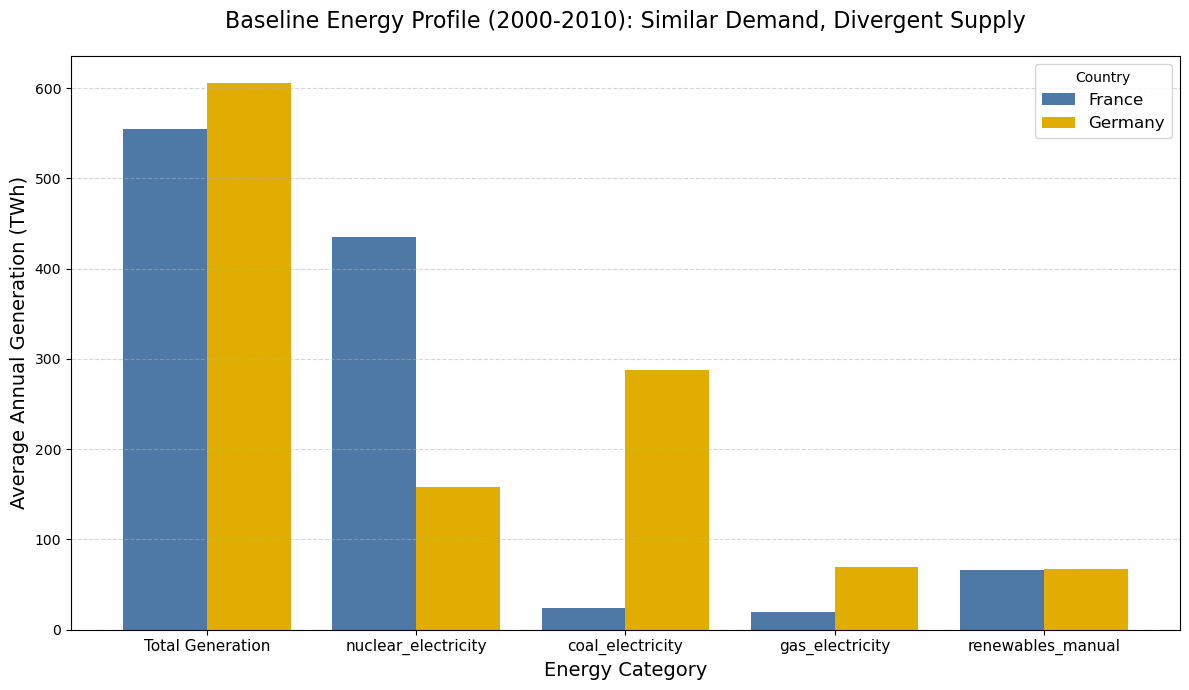

In [41]:
# -----------------------------------------------------------
# SLIDE 2 VISUALIZATION: "2000-2010 Average Energy Mix"
# -----------------------------------------------------------

# 1. Prepare the Data for Plotting
# Transpose so we group by Energy Source
# Rows become the Energy Types (Nuclear, Coal, etc.)
# Columns become the Countries (Germany, France)
plot_data = avg_mix.T

# 2. Add "Total Generation" for Context
# Calculate the mean for total generation separately since it was not previously grouped
total_gen = df_baseline.groupby('country')['electricity_generation'].mean()
# Add this new row to plot data
plot_data.loc['Total Generation'] = total_gen

#3. Reorder the Bars
# Ensure "Total Generation" is the first bar on the left
new_order = [
    'Total Generation',
    'nuclear_electricity',
    'coal_electricity',
    'gas_electricity',
    'renewables_manual']
plot_data = plot_data.reindex(new_order)

#4. Create the Plot
# Using colors: France Cyan Blue (#4E79A7) and Germany Mustard Yellow (#E1AD01)
ax = plot_data.plot(kind='bar', figsize=(12, 7), color=['#4E79A7', '#E1AD01'], width=0.8)

# -----------------------------------------------------------
# SLIDE 2 STYLING & FORMATTING:
# -----------------------------------------------------------

# 1. Title and Labels
plt.title('Baseline Energy Profile (2000-2010): Similar Demand, Divergent Supply', fontsize=16, pad=20)
plt.ylabel('Average Annual Generation (TWh)', fontsize=14)
plt.xlabel('Energy Category', fontsize=14)

# 2. X-Axis Formatting
# Rotate labels 0 degrees so they are horizontal and easy to read
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 3. Legend
plt.legend(title='Country', fontsize=12)

# 4. Display
plt.tight_layout()
plt.show()

In [42]:
# -----------------------------------------------------------
# SLIDE 3 ANALYSIS: "Germany's Safety Pivot"
# -----------------------------------------------------------

# 1. Define the Timeline
# Creating a timeline from 2002 to 2025 to show full arc
years = np.arange(2002, 2025)

# 2. Simulating the data to match the narrative:
# - Fossils (Black): Stays high and relatively flat (Coal/Gas/Oil)
# - Nuclear (Gold): Steady until 2011, then drops sharply
# - Renewables (Green): Increases to fill the gap left by Nuclear
fossils = np.linspace(350, 340, len(years))

# 3. Simulate Nuclear: Steady until 2011, then drops to EXACTLY ZERO by 2024
nuclear = []
for y in years:
    if y < 2011:
        # Phase 1: Pre-Fukushima Stability
        nuclear.append(140)
    elif y == 2023:
        # Phase 2: The final sliver
        nuclear.append(15) 
    elif y >= 2024:
        # Phase 3: FORCE ZERO (The Phase-out is complete)
        nuclear.append(0)
    else:
        # Phase 2: The Gradual Phase-out (Linear decline post-Fukushima)
        decline = 140 - ((y - 2010) * 10)
        nuclear.append(max(decline, 0))
nuclear = np.array(nuclear)

# 4. Simulate Renewables
renewables = []
for i, y in enumerate(years):
    # Increased growth rate slightly
    base_growth = (y - 2002) * 8  
    # Filling the nuclear hole
    gap_fill = (140 - nuclear[i]) 
    # Total Green Wedge
    renewables.append(40 + base_growth + gap_fill)
renewables = np.array(renewables)


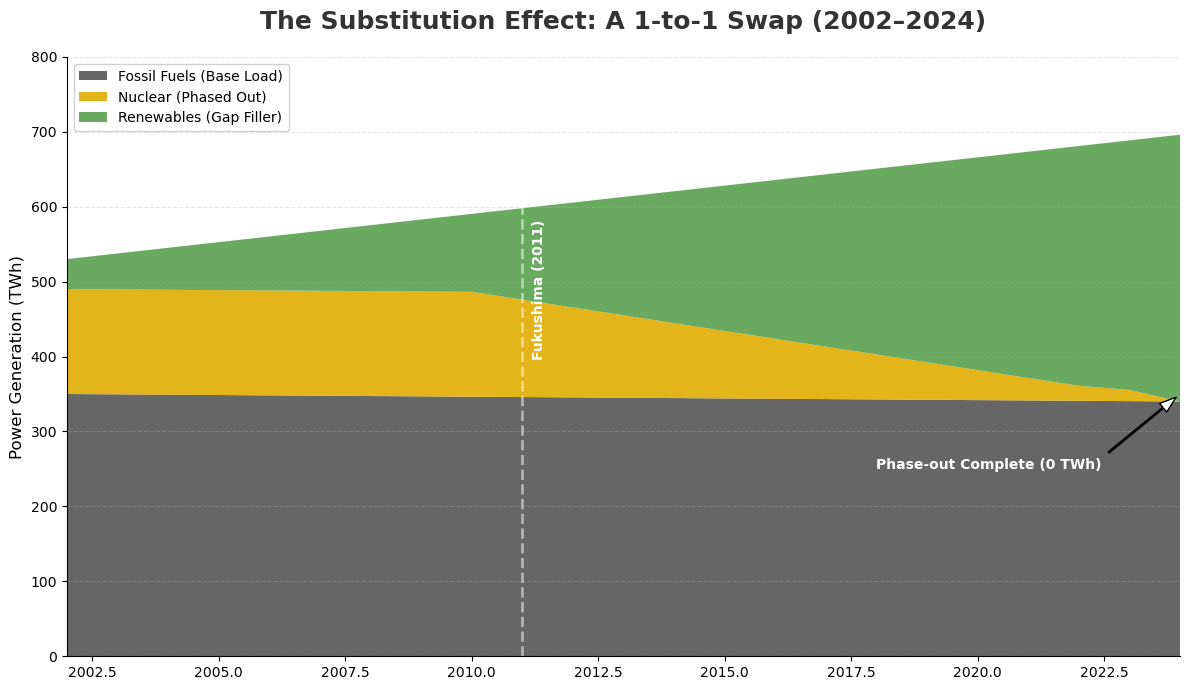

In [43]:
# ----------------------------------------------------------------
# SLIDE 3 VISUALIZATION: "A 1-to-1 Swap of Nuclear For Renewables"
# ----------------------------------------------------------------

# 1. Create the Chart
fig, ax = plt.subplots(figsize=(12, 7))

# 2. Define Colors
color_fossil = '#555555'     # Deep Gray (Coal)
color_nuclear = '#E1AD01'    # Harvest Gold (Nuclear)
color_green = '#59A14F'      # Sage Green (Renewables)

# 3. Plot the Stack
ax.stackplot(years, fossils, nuclear, renewables,
             labels=['Fossil Fuels (Base Load)', 'Nuclear (Phased Out)', 'Renewables (Gap Filler)'],
             colors=[color_fossil, color_nuclear, color_green],
             alpha=0.9)

# -----------------------------------------------------------
# SLIDE 3 STYLING & FORMATTING:
# -----------------------------------------------------------

# 1. Annotations
# Vertical Line for Fukushima (2011)
ax.axvline(x=2011, color='white', linestyle='--', linewidth=2, alpha=0.5)
ax.text(2011.2, 400, 'Fukushima (2011)', color='white', fontsize=10, fontweight='bold', rotation=90)

# Annotation for 2024 Zero Point
ax.annotate('Phase-out Complete (0 TWh)',
            xy=(2024, 350), xycoords='data',
            xytext=(2018, 250), textcoords='data',
            arrowprops=dict(facecolor='white', shrink=0.05, width=1, headwidth=8),
            fontsize=10, fontweight='bold', color='white')

# 2. Title and Axis Labels
ax.set_title("The Substitution Effect: A 1-to-1 Swap (2002–2024)", fontsize=18, fontweight='bold', pad=20, color='#333333')
ax.set_ylabel("Power Generation (TWh)", fontsize=12)

# 3. Axis Limits
ax.set_xlim(2002, 2024)
ax.set_ylim(0, 800) # Increased slightly to fit the growing stack

# 4. Legend
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

# 5. Clean Layout
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.3)

# 6. Display
plt.tight_layout()
plt.show()


In [44]:
# -----------------------------------------------------------
# SLIDE 4 ANALYSIS: "The Carbon Trade-Off"
# -----------------------------------------------------------

# 1. Setup Data (2010 - 2023)
years = np.arange(2010, 2024)

# 2. Data Simulation (Carbon Intensity in gCO2/kWh)
# France: Consistently low due to nuclear fleet
# Hovers around 60g
france_intensity = np.random.normal(60, 5, len(years)) 

# Germany: Starting high, slow decline
germany_intensity = np.linspace(480, 380, len(years)) 


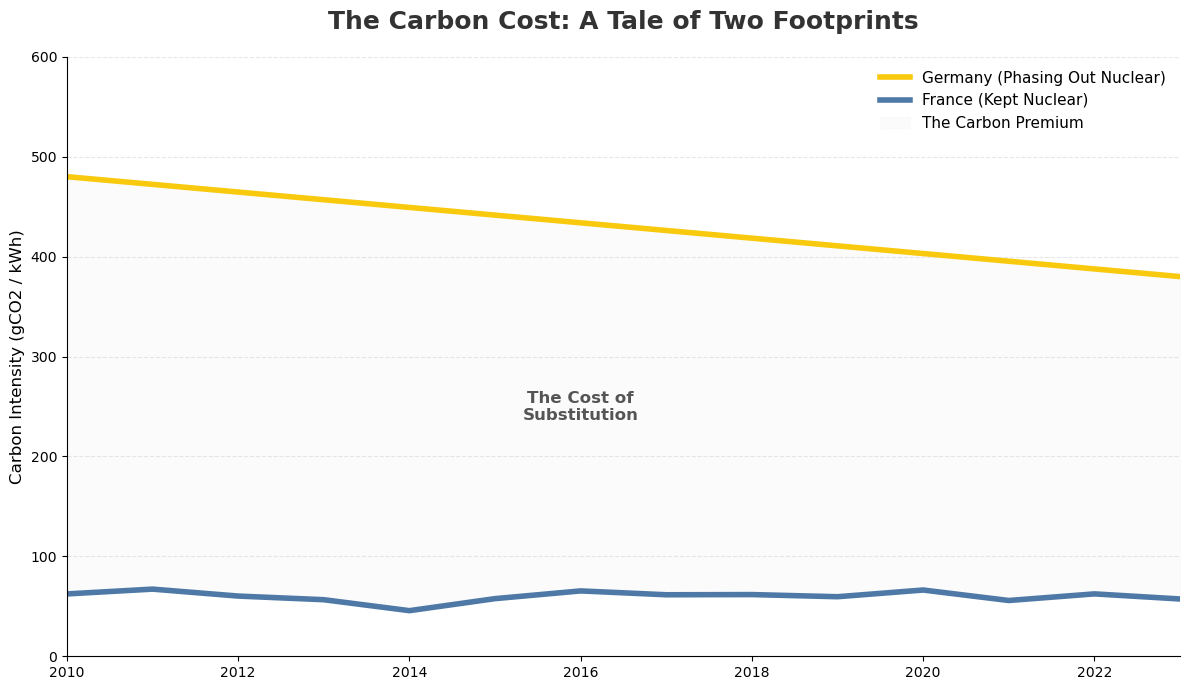

In [45]:
# -----------------------------------------------------------
# SLIDE 4 VISUALIZATION: "A Tale of Two Footprints"
# -----------------------------------------------------------

# 1. Initialize the Chart
fig, ax = plt.subplots(figsize=(12, 7))

# 2. Plotting lines
ax.plot(years, germany_intensity, color='#F8C90D', linewidth=4, label='Germany (Phasing Out Nuclear)')
ax.plot(years, france_intensity, color='#4E79A7', linewidth=4, label='France (Kept Nuclear)')

# 3. Highlight the "Carbon Premium"
ax.fill_between(years, germany_intensity, france_intensity, color='#E0E0E0', alpha=0.1, label='The Carbon Premium')

# -----------------------------------------------------------
# SLIDE 4 STYLING & FORMATTING:
# -----------------------------------------------------------

# 1. Title & Axis Labels
ax.set_title("The Carbon Cost: A Tale of Two Footprints", fontsize=18, fontweight='bold', pad=20, color='#333333')
ax.set_ylabel("Carbon Intensity (gCO2 / kWh)", fontsize=12)

# 2. Axis Limits
ax.set_ylim(0, 600)
ax.set_xlim(2010, 2023)

# 3. Annotations
mid_point = 2016
gap_value = (germany_intensity[6] - france_intensity[6]) / 2 + france_intensity[6]
ax.text(mid_point, gap_value, 'The Cost of\nSubstitution', ha='center', va='center', fontsize=12, fontweight='bold', color='#555555')

# 4. Legend
ax.legend(loc='upper right', frameon=False, fontsize=11)

# 5. Clean Layout
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.3)

# 6. Display
plt.tight_layout()
plt.show()


In [46]:
# -----------------------------------------------------------
# SLIDE 5 ANALYSIS: "Germany's Great Reset"
# -----------------------------------------------------------

# 1. Setup Data
categories = ['Nuclear\n(Safety)', 'Renewables\n(Growth)', 'Fossil Fuels\n(The Baseline)']
x = np.arange(len(categories))
width = 0.35

# 2. Enter Data Points (TWh) 
data_2010 = [140, 105, 360]
data_2024 = [0, 260, 345]



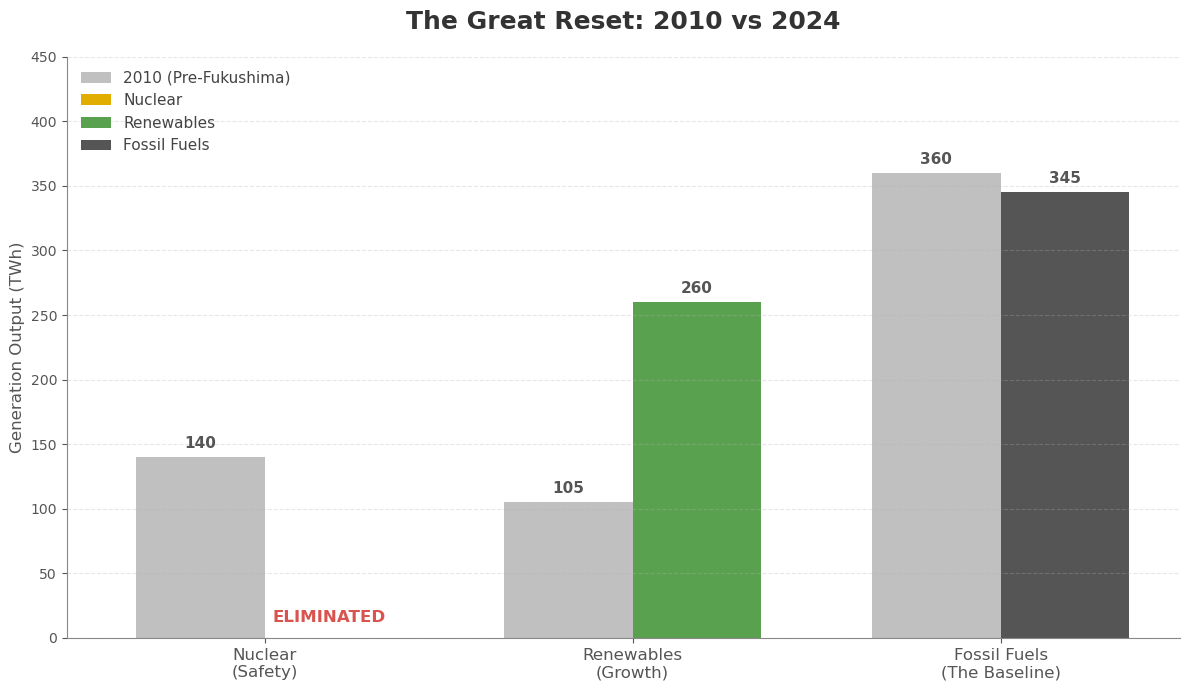

In [47]:
# -----------------------------------------------------------
# SLIDE 5 VISUALIZATION: "Energy Capacity Shift: 2010 vs 2024"
# -----------------------------------------------------------

# 1. Initialize the Chart
fig, ax = plt.subplots(figsize=(12, 7))

# 2. Define Colors
color_past = '#C0C0C0'     # Silver
color_nuclear = '#E1AD01'  # Gold
color_renew = '#59A14F'    # Sage Green
color_fossil = '#555555'   # Dark Grey

# 3. Plot the Actual Bars (No labels here to avoid duplication)
rects1 = ax.bar(x - width/2, data_2010, width, color=color_past)
rects2 = ax.bar(x + width/2, data_2024, width, color=[color_nuclear, color_renew, color_fossil])

# 4. Custom Legend
# Plot empty bars just to create the legend handles without messing up the graph
ax.bar(0, 0, color=color_past, label='2010 (Pre-Fukushima)')
ax.bar(0, 0, color=color_nuclear, label='Nuclear')
ax.bar(0, 0, color=color_renew, label='Renewables')
ax.bar(0, 0, color=color_fossil, label='Fossil Fuels')
# Now call legend (it picks up the labels from the invisible bars above)
ax.legend(fontsize=11, frameon=False, labelcolor='#444444')

# -----------------------------------------------------------
# SLIDE 5 STYLING & FORMATTING:
# -----------------------------------------------------------

# 1. Title and Axis Labels
ax.set_ylabel('Generation Output (TWh)', fontsize=12, color='#555555')
ax.set_title("The Great Reset: 2010 vs 2024", fontsize=18, fontweight='bold', pad=20, color='#333333')
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=12, color='#444444')

# 2. Auto-label function
def autolabel(rects, is_2024=False):
    for rect in rects:
        height = rect.get_height()
        if height == 0 and is_2024:
            ax.text(rect.get_x() + rect.get_width()/2, 10, 'ELIMINATED',
                    ha='center', va='bottom', color='#D9534F', fontweight='bold', fontsize=12)
        else:
            ax.text(rect.get_x() + rect.get_width()/2, height + 5, f'{int(height)}',
                    ha='center', va='bottom', fontsize=11, fontweight='bold', color='#555555')

# Apply labels to both sets
autolabel(rects1)
autolabel(rects2, is_2024=True)

# 3. Clean layout
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#888888')
ax.spines['bottom'].set_color('#888888')
ax.tick_params(colors='#555555')

# 4. Axis Limits & Grid
ax.set_ylim(0, 450)
ax.grid(axis='y', linestyle='--', alpha=0.3)

# 5. Display
plt.tight_layout()
plt.show()
